<h1 align="center">Rwanda Maize–Urea Trial</h1>
<h2 align="center">1. Data Audit</h2>

**Goal:** understand the structure and quality of the three source tables before changing anything.

Questions this notebook answers:
1. What is the grain (one row = what?) of each table, and are the keys unique?
2. Does the data reflect the trial design (four plots, four treatments per field)?
3. Do the tables join cleanly?
4. Where is data missing, and is the missingness random or systematic?
5. Are any values implausible?

Every finding is written to the **[data audit log](../01_Data/audit/data_audit_log.md)**, which is rebuilt from the data each time the pipeline runs.

> **Data note.** The trial data is confidential and is not in this repository. The outputs shown come from the **synthetic sample** in `01_Data/sample/`, which has the same structure and data-quality problems as the real data. The numbers illustrate the method; they are not Evergreen's actual results.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "02_Notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from maize import config, data, audit, plotting

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
MODE = config.data_mode()
OUT = config.output_paths(MODE)
print("Data source:", "confidential trial data (01_Data/raw)" if MODE == "raw" 
      else "synthetic sample (01_Data/sample)")

Data source: synthetic sample (01_Data/sample)


## 1. Inventory

In [2]:
src = data.load_sources(MODE)
pd.DataFrame({name: {"rows": df.shape[0], "columns": df.shape[1]} for name, df in src.items()}).T

,rows,columns
field,397,19
plot,1590,27
soil,685,5


## 2. Grain and keys

Expected grain: one row per **field-season** (`block_id` + `season`) in the field table, and one row per **plot** (`plot_id`) in the plot table.

In [3]:
field, plot, soil = src["field"], src["plot"], src["soil"]
pd.Series({
    "Duplicate field keys (block_id, season)": field.duplicated(["block_id", "season"]).sum(),
    "block_id repeated across seasons": field["block_id"].duplicated().sum(),
    "Duplicate plot_id": plot["plot_id"].duplicated().sum(),
    "Duplicate soil plot_id": soil["plot_id"].duplicated().sum(),
    "Complete duplicate rows (all tables)": field.duplicated().sum() + 
    plot.duplicated().sum() + soil.duplicated().sum(),
}, name="count").to_frame()

,count
"Duplicate field keys (block_id, season)",0
block_id repeated across seasons,0
Duplicate plot_id,0
Duplicate soil plot_id,0
Complete duplicate rows (all tables),0


All keys are unique, so each table can be joined without creating duplicate rows.

## 3. Does the data match the trial design?

Each field-season should have four plots, one for each treatment.

In [4]:
per_unit = plot.groupby(["block_id", "season"])["treat_code"].nunique()
display(per_unit.value_counts().rename_axis("treatments per field-season").to_frame("units"))
plot["urea_rate_timing"].map(config.TREATMENT_LABELS).value_counts().sort_index().to_frame("plots")

,units
treatments per field-season,
4,394
3,4
2,1


,plots
urea_rate_timing,
"A: 50 kg/ha, all at V6",399
"B: 100 kg/ha, planting + V6",394
"C: 100 kg/ha, V6 + V10",399
"D: 100 kg/ha, all at V6",398


The design holds for almost every unit. A handful have only two or three treatments; they are kept and flagged (we want to handle unbalanced units later when we prepare the mixed model). Treatments are well balanced overall.

## 4. Do the tables join cleanly?

In [5]:
keys = field[["block_id", "season"]]
joined = plot.merge(keys, on=["block_id", "season"], how="left", indicator=True)
orphans = joined[joined["_merge"] == "left_only"]
pd.Series({
    "Plots without a field record": len(orphans),
    "...in field-season units": orphans[["block_id", "season"]].drop_duplicates().shape[0],
    "...whose block_id appears in another season": orphans["block_id"].isin(field["block_id"]).sum(),
    "Soil records without a matching plot": (~soil["plot_id"].isin(plot["plot_id"])).sum(),
    "Plots with a soil record": plot["plot_id"].isin(soil["plot_id"]).sum(),
}, name="count").to_frame()

,count
Plots without a field record,8
...in field-season units,2
...whose block_id appears in another season,0
Soil records without a matching plot,0
Plots with a soil record,685


A few plots belong to fields that are missing from the field table entirely, so they have no mega-environment. They stay in the dataset with a flag but cannot enter the adjusted models. Soil was measured on fewer than half of the plots.

## 5. Missingness

The question is not only *how much* is missing but *whether the pattern is systematic*, because that decides whether imputation is safe.

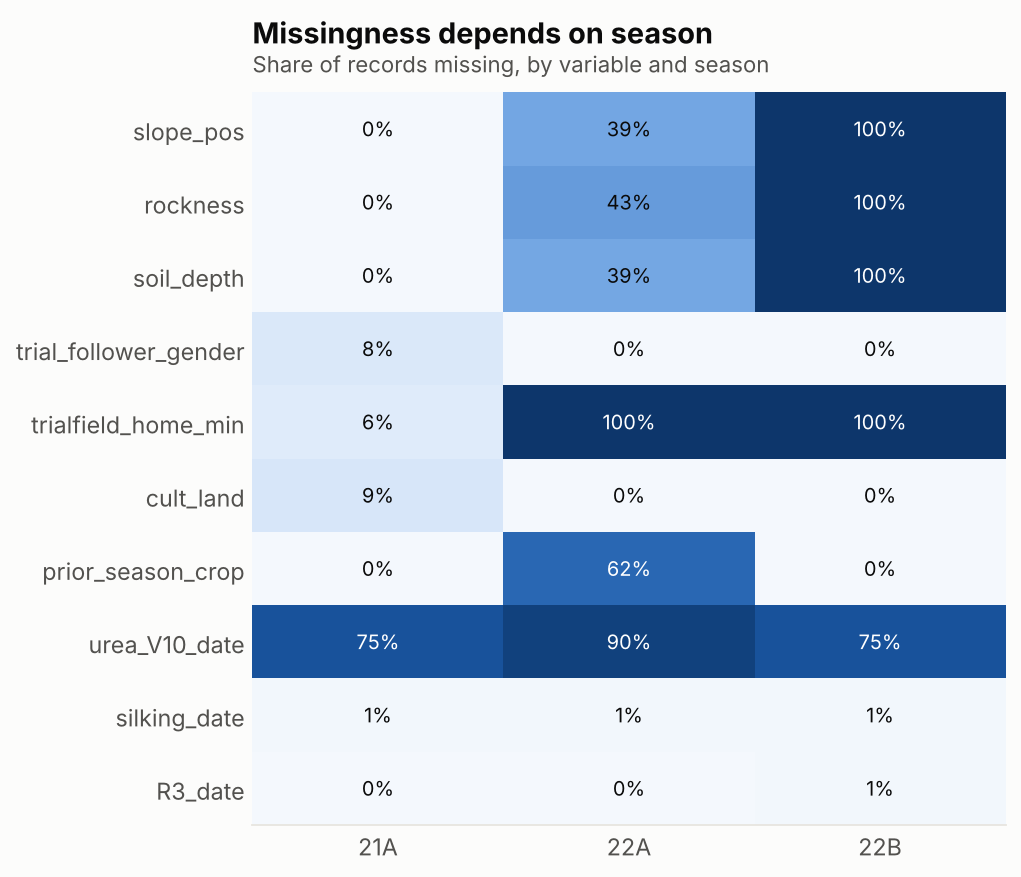

In [6]:
plotting.missingness_by_season(field, plot, OUT.figures / "missingness_by_season.png")
display(Image(OUT.figures / "missingness_by_season.png", width=620))

Missingness follows the **season**, not the field:
* `slope_pos`, `rockness` and `soil_depth` were collected in 21A, partly in 22A and not at all in 22B.
* `trialfield_home_min` was only collected in 21A.
* `prior_season_crop` is missing only in 22A.

These variables are missing by design, so we won't want to **impute** them in the treatment models. We would, however, want to impute them in the prediction model, inside each cross-validation fold.

The V10 date looks 75–90% missing, but most of that is structural, because only one treatment has a V10 dose:

In [7]:
v10 = plot[plot["urea_V10_kgha"] > 0]
v10.assign(date_missing=v10["urea_V10_date"].isna()).groupby("season")["date_missing"].agg(["sum", "size", "mean"]) \
   .rename(columns={"sum": "missing V10 date", "size": "V6+V10 plots", "mean": "share"})

,missing V10 date,V6+V10 plots,share
season,,,
21A,0,127,0.000
22A,115,193,0.596
22B,0,79,0.000


The real issue is narrow: all of the missing V10 dates in V6+V10 plots are in **22A**, and the quantity was still recorded. This looks like a recording gap for one season, not a missed application. We want to leave the dates as missing, not imputed.

In [8]:
soil_cov = plot.assign(has_soil=plot["plot_id"].isin(soil["plot_id"]))
soil_cov.groupby("season")["has_soil"].mean().to_frame("share of plots with soil data")

,share of plots with soil data
season,
21A,0.747
22A,0.246
22B,0.375


Soil coverage varies a lot by season, so the plots with soil data are **not a representative subset**. Soil pH is used only in soil-specific checks, and we'll want to do a full coverage from SoilGrids later on in the analysis process.

## 6. Implausible values

In [9]:
display(plot["yield_tha"].describe().to_frame("yield_tha").T)
print("Five highest yields (t/ha):", plot["yield_tha"].nlargest(5).tolist())
print("Fields with altitude below 900 m:", int((field["alt"] < config.IMPLAUSIBLE_ALTITUDE_M).sum()),
      "->", field.loc[field["alt"] < config.IMPLAUSIBLE_ALTITUDE_M, "alt"].tolist())
print("Crop labels:", plot["crop"].value_counts().to_dict())

Five highest yields (t/ha): [55.0, 11.36, 11.03, 10.61, 10.6]
Fields with altitude below 900 m: 3 -> [0.26, 0.0, 0.26]
Crop labels: {'Maize': 821, 'maize': 769}


,count,mean,std,min,25%,50%,75%,max
yield_tha,1590.0,5.214,2.027,0.4,4.11,5.08,6.18,55.0


* **One yield of 55 t/ha**, against a next-highest value of about 11 t/ha. This is almost certainly a misplaced decimal point (5.5). It is kept, and every key result is reported with and without it.
* **Three altitudes of 0 – 0.26 m.** Rwanda's lowest point is around 950 m, so these are GPS defaults. They are set to missing in `alt_clean`.
* **'Maize' and 'maize'** are both used as crop labels. We'll want to standardize them later when cleaning the data.

## 7. Audit log

All checks are run by `maize.audit.run_audit`, which writes the log as Markdown (for reading) and CSV (for filtering).

In [10]:
cleaned, combined = data.build_combined(MODE)
log = audit.run_audit(src, cleaned, combined)
audit.write_audit_log(log, OUT.audit, "confidential trial data" if MODE == "raw" else "synthetic sample data")
log[["issue_id", "area", "check_performed", "finding", "records_affected", "severity", "status"]]

,issue_id,area,check_performed,finding,records_affected,severity,status
0,AUD-01,Structure,Row counts per table,"397 field, 1,590 plot and 685 soil records",0,Info,Confirmed - no issue
1,AUD-02,Structure,Key uniqueness and complete-row duplicates,"0 duplicate field keys, 0 duplicate plot IDs, ...",0,Low,Confirmed - no issue
2,AUD-03,Integrity,Every plot has a field record,8 plots in 2 field-season units have no field ...,8,High,Resolved
3,AUD-04,Integrity,Every soil record matches a plot,0 soil records without a matching plot,0,Low,Confirmed - no issue
4,AUD-05,Design,Four plots / four treatments per field-season ...,394/399 (98.7%) units complete; 5 units have 2...,14,Medium,Resolved
5,AUD-06,Design,Treatment balance,"Four treatments, 394-399 plots each",0,Info,Confirmed - no issue
6,AUD-07,Dates,Data types,7 date columns stored as text; all non-missing...,0,Low,Confirmed - no issue
7,AUD-08,Dates,Growth-stage dates in a plausible order,3 violations (R3 before silking: 3),3,Medium,Resolved
8,AUD-09,Dates,Missing values,9 plots have no silking date,9,Low,Resolved
9,AUD-10,Dates,Missing values,4 plots have no R3 date,4,Low,Resolved


## Summary

| Area | Conclusion |
|---|---|
| Structure | Keys are unique; no duplicate rows |
| Design | The four-treatment design holds for ~99% of field-seasons; incomplete units are flagged |
| Integrity | A few plots have no field record; they are flagged and kept |
| Missingness | Systematic by season, so no imputation in the treatment models |
| Soil | Measured on under half the plots, unevenly; N, organic C and sand are empty → SoilGrids |
| Values | One implausible yield and three implausible altitudes are flagged; labels are standardised |

**Next:** notebook 02 applies these decisions.